In [28]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2
from fwh_analysis import FWHDataset, FWHPlotter


def fft(dataset, col='P_obs', title="FFT Spectrum", max_freq=None, auto_scale=True):
    if type(dataset) == pd.DataFrame:
        time = dataset['Time'].values
        pressure = dataset[col].values
    elif type(dataset) == FWHDataset:
        time = dataset.data['Time'].values
        pressure = dataset.data[col].values
    
    dt = time[1] - time[0]
    N = len(time)
    
    freqs = np.fft.rfftfreq(N, d=dt)
    fft_complex = np.fft.rfft(pressure)
    
    amplitude = 2.0 / N * np.abs(fft_complex)
    amplitude[0] = amplitude[0] / 2
    phases = np.angle(fft_complex)
    
    if auto_scale and max_freq is None:
        max_amp = np.max(amplitude)
        threshold = max(0.01 * max_amp, 1e-3) 
        
        significant_indices = np.where(amplitude > threshold)[0]
        
        if len(significant_indices) > 0:
            highest_significant_freq = freqs[significant_indices[-1]]
            max_freq = min(highest_significant_freq * 1.15, freqs[-1])
        else:
            max_freq = freqs[-1]  # Fallback if flatline

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(freqs, amplitude, linestyle='-', color='b', markersize=4)
    
    ax.set_title(title, weight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (Pa)')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if max_freq:
        ax.set_xlim(left=0, right=max_freq)
        
    plt.tight_layout()
    plt.show()
    
    return freqs, amplitude, phases

def dft(t, p, f_1bpf, num_harmonics=10):
    if type(t) == pd.core.series.Series:
        T_period = t.iloc[-1] - t.iloc[0]
    elif type(t) == list:
        T_period = t[-1] - t[0]
    freqs = np.zeros(num_harmonics)
    amps = np.zeros(num_harmonics)
    phases = np.zeros(num_harmonics)

    for n in range(1, num_harmonics + 1):
        freqs[n-1] = n * f_1bpf
        omega_n = 2 * np.pi * freqs[n-1]

        real = np.trapezoid(p * np.cos(omega_n * t), t) * (2.0 / T_period)
        imag = np.trapezoid(p * np.sin(omega_n * t), t) * (2.0 / T_period)

        amps[n-1] = np.sqrt(real ** 2 + imag **2)
        phases[n-1] = np.arctan2(-imag, real)

    return freqs, amps, phases

def dft_spatial(theta_rad, p_theta, num_modes):
    theta_full = np.append(theta_rad, 2 * np.pi)
    p_full = np.append(p_theta, p_theta[0])
    
    modes = np.arange(1, num_modes + 1)
    amps = np.zeros(num_modes)
    phases = np.zeros(num_modes)

    for i, m, in enumerate(modes):
        real = np.trapezoid(p_full * np.cos(m * theta_full), theta_full) / np.pi
        imag = np.trapezoid(p_full * np.sin(m * theta_full), theta_full) / np.pi

        amps[i] = np.sqrt(real **2 + imag **2)
        phases[i] = np.arctan2(-imag, real)

    return modes, amps, phases

def dft_plot(freqs, amps, analysis='temporal', scale='linear'):
    if scale == 'linear':
        pass
    elif scale == 'db':
        p_ref = 2e-5
        amps = 20 * np.log10((amps / np.sqrt(2)) / p_ref)

    fig, ax = plt.subplots(figsize=(8,5))
    markerline, stemlines, baseline = ax.stem(freqs, amps, basefmt=' ')
    plt.setp(markerline, marker='o', color='red', markersize=6)
    plt.setp(stemlines, color='black', ls='--', linewidth=1.2)

    for x, y in zip(freqs, amps):
        y_offset = max(amps) * 0.05
        if y < 0:
            y = 0
        ax.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=9)

    if analysis == 'temporal':
        ax.set_xlabel('Frequency (Hz)', fontweight='bold')
        ax.set_title(f"DFT Extraction ({len(freqs)}) Harmonics, Base Frequency = {freqs[0]} Hz")
    elif analysis == 'spatial':
        ax.set_xlabel('Modes', fontweight='bold')
        ax.set_title(f'DFT Extraction of Spatial Periodicity')

    ax.set_ylabel('Amplitdue (Pa)' if scale == 'linear' else 'Sound Pressure Level (dB), Reference = 2e-5 Pa', fontweight='bold')
    
    ax.set_ylim(0, max(amps) * 1.2)
    ax.set_xticks(freqs)
    # ax.set_xticks(i for i in range(len(freqs)))
    plt.xticks(rotation=45)
    ax.grid(True, ls=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

def box_plotter(target_directory, target_observers=None, use_doppler=True, add_title=None):
    # 1. Compile the entire directory using the upgraded batch method
    master = FWHDataset.compile_fwh_batch(target_directory, use_doppler=use_doppler)
    df = pd.DataFrame(master)
    
    # 2. Filter by requested observers
    if target_observers:
        # Standardize inputs to zero-padded strings (e.g., 1 -> '01')
        target_observers = [str(obs).zfill(2) for obs in target_observers]
        df = df[df['observer'].isin(target_observers)]
        
    # Sort dataframe so the x-axis plots sequentially
    df = df.sort_values(by='observer')

    # 3. Generate Boxplot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.boxplot(data=df, x='observer', y='error', palette='coolwarm', 
                boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
                showfliers=False, ax=ax)

    # 4. Calculate and Stamp Medians
    medians = df.groupby('observer')['error'].median()
    obs_names = sorted(df['observer'].unique())

    for i, obs in enumerate(obs_names):
        median_val = medians[obs]
        text_label = f"{median_val:.2e}" 
        ax.text(i, median_val * 1.05, text_label, 
                horizontalalignment='center', size='small', color='black', weight='bold')

    ax.set_yscale('log')
    ax.set_ylabel('L2 Error (%)')
    
    # Optional: Auto-scale y-limit if the hardcoded bounds clip your multipole data
    # ax.set_ylim(df['error'].min() * 0.5, df['error'].max() * 2.0)
    ax.set_ylim(5e-4, 5e-2) 
    
    ax.set_xlabel('Observer ID')
    ax.set_title(f'Observer Error Variance | {add_title if add_title else None}')
    ax.grid(True, axis='y', linestyle='--', alpha=0.6, which='both')

    plt.tight_layout()
    plt.show()
    
    return df

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


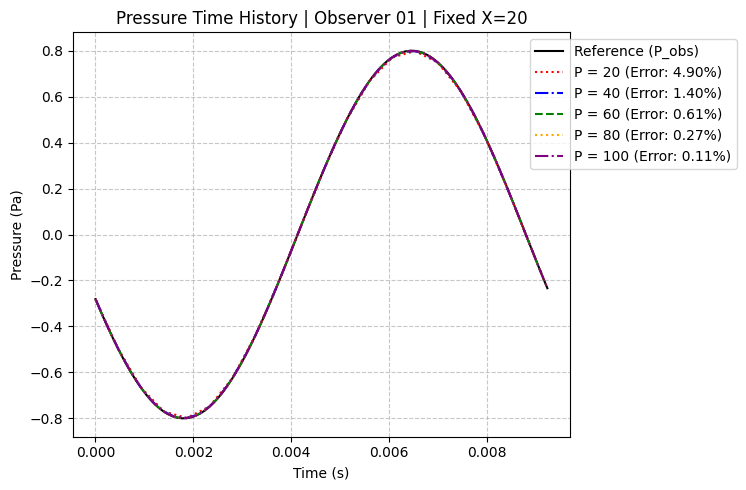

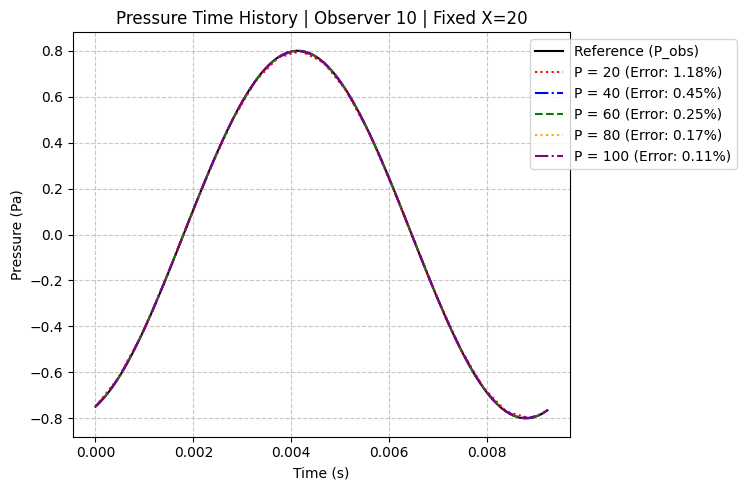

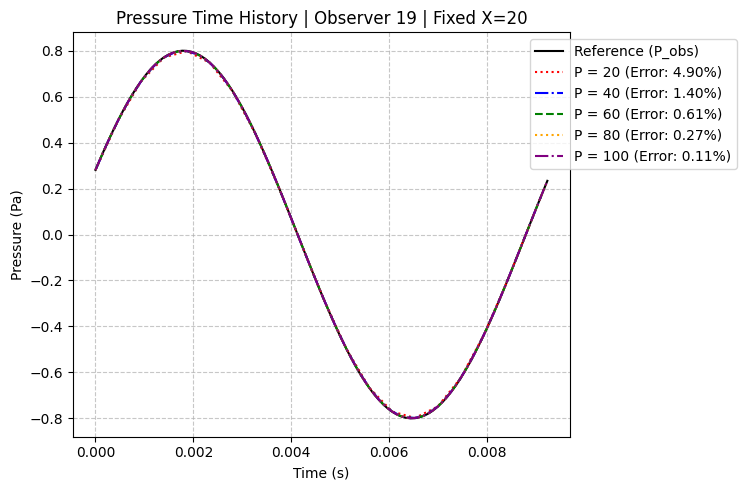

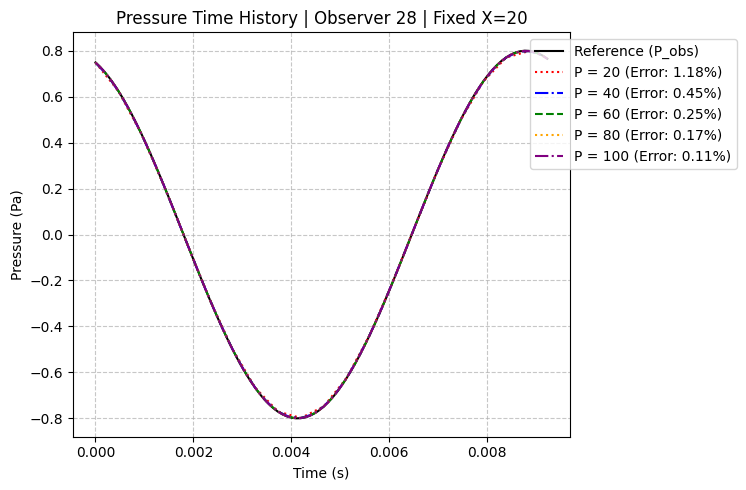

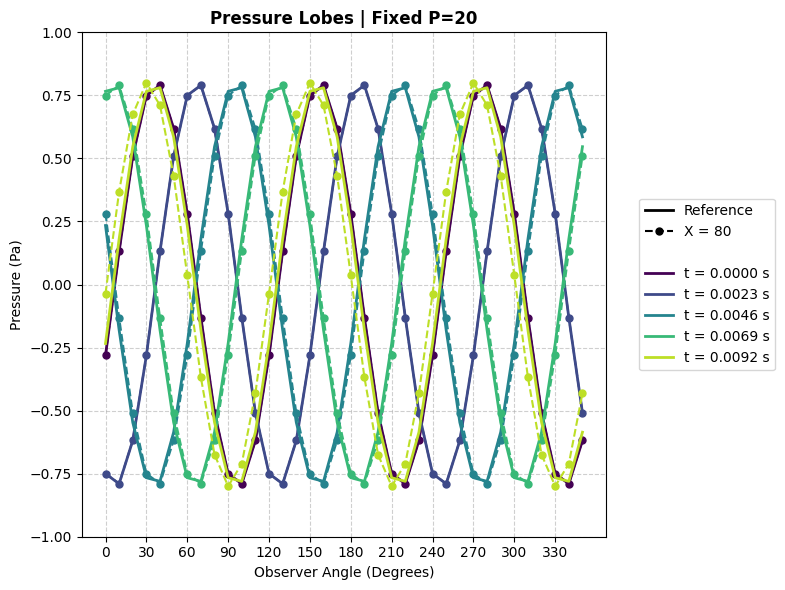

In [2]:
date = '260722'
filepath = Path(f'data_{date}/36sources_xpsweep')
obs_id = ['01','10','19','28']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 20
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | Observer {obs} | Fixed X={x_fixed}',
        error_method='l2'
    )

# ==========================================
# 2. Spatial Directivity (Fixed P, Varying X)
# ==========================================
p_fixed = 20
x_test_vals = [80]#[20, 40, 60, 80, 100]

# Build reference dataset ring (36 observers)
ana_datasets = [FWHDataset(filepath=filepath / f'ana_spatial_{i:02d}.dat') for i in range(1, 37)]

# Build comparison dataset rings dynamically
comp_datasets = []
comp_labels = []

for x in x_test_vals:
    # Check if the entire 36-observer ring exists for this X value
    x_ring_paths = [filepath / f'X{x}_P{p_fixed}_{i:02d}.dat' for i in range(1, 37)]
    
    if all(path.exists() for path in x_ring_paths):
        comp_datasets.append([FWHDataset(filepath=path) for path in x_ring_paths])
        comp_labels.append(f'X = {x}')
    else:
        print(f"Skipping X = {x} (incomplete or missing observer files).")

obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

t_period = datasets[0].data['Time'].max()
# target_times = (0.011, 0.022, 0.033, 0.045)
snapshot_times = np.linspace(0, t_period, num=5)
# for target_time in target_times:
    # Plot using the updated class method
FWHPlotter.plot_directivity_snapshot(
    ana_datasets,
    *comp_datasets,
    target_time=snapshot_times, # Interpolates all datasets to this exact steady-state timestamp
    labels=comp_labels,
    title=f'Pressure Lobes | Fixed P={p_fixed}',
    col='P_obs', 
    is_polar=False,
    legend=True,
    ylim=1.0
)



DEBUG: Loaded References: ['obs_29', 'obs_33', 'obs_02', 'obs_22', 'obs_03', 'obs_11', 'obs_26', 'obs_27', 'obs_19', 'obs_21', 'obs_32', 'obs_08', 'obs_09', 'obs_10', 'obs_23', 'obs_12', 'obs_06', 'obs_13', 'obs_17', 'obs_35', 'obs_05', 'obs_36', 'obs_30', 'obs_20', 'obs_24', 'obs_25', 'obs_18', 'obs_04', 'obs_34', 'obs_01', 'obs_15', 'obs_31', 'obs_16', 'obs_14', 'obs_28', 'obs_07']


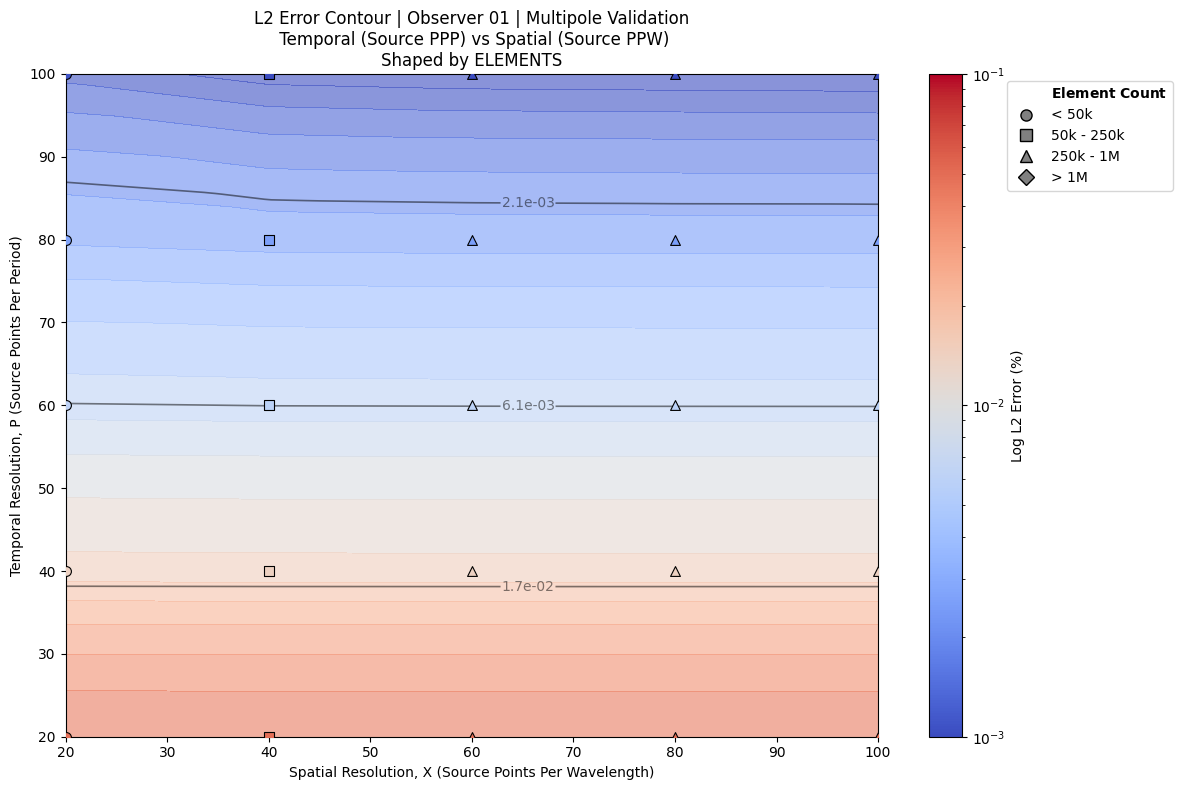

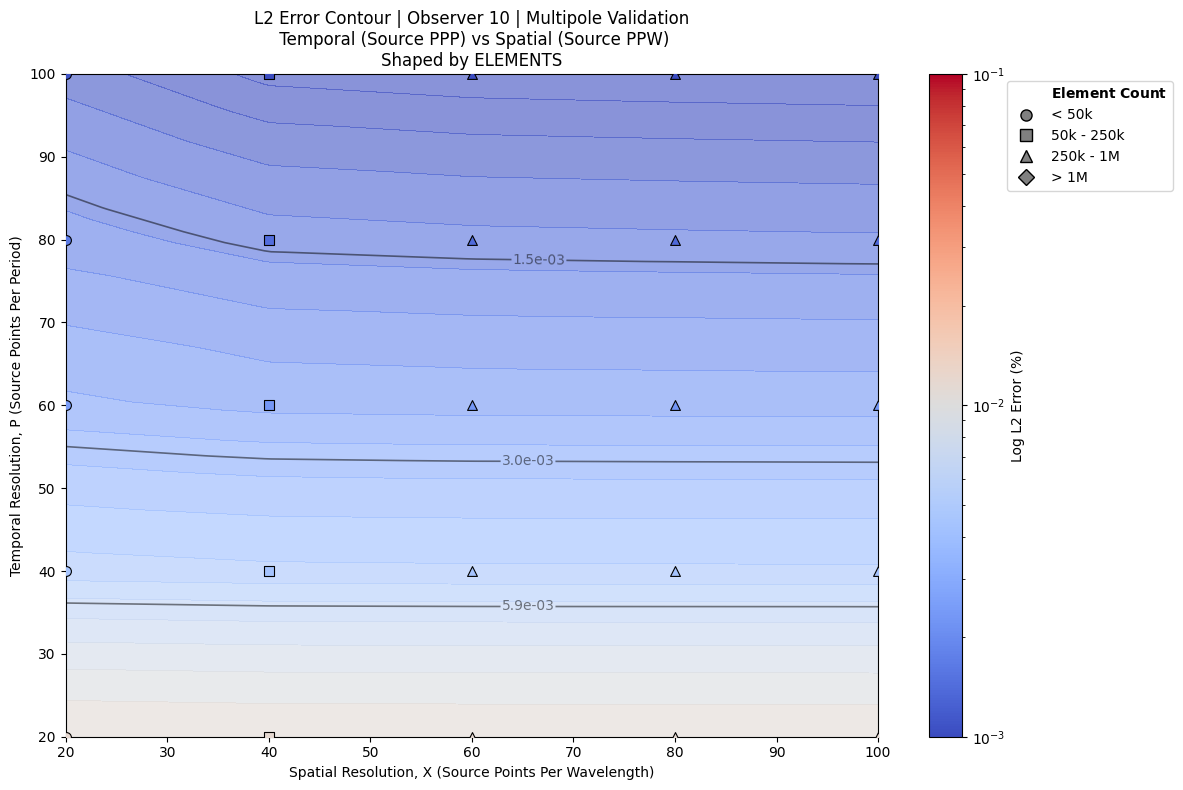

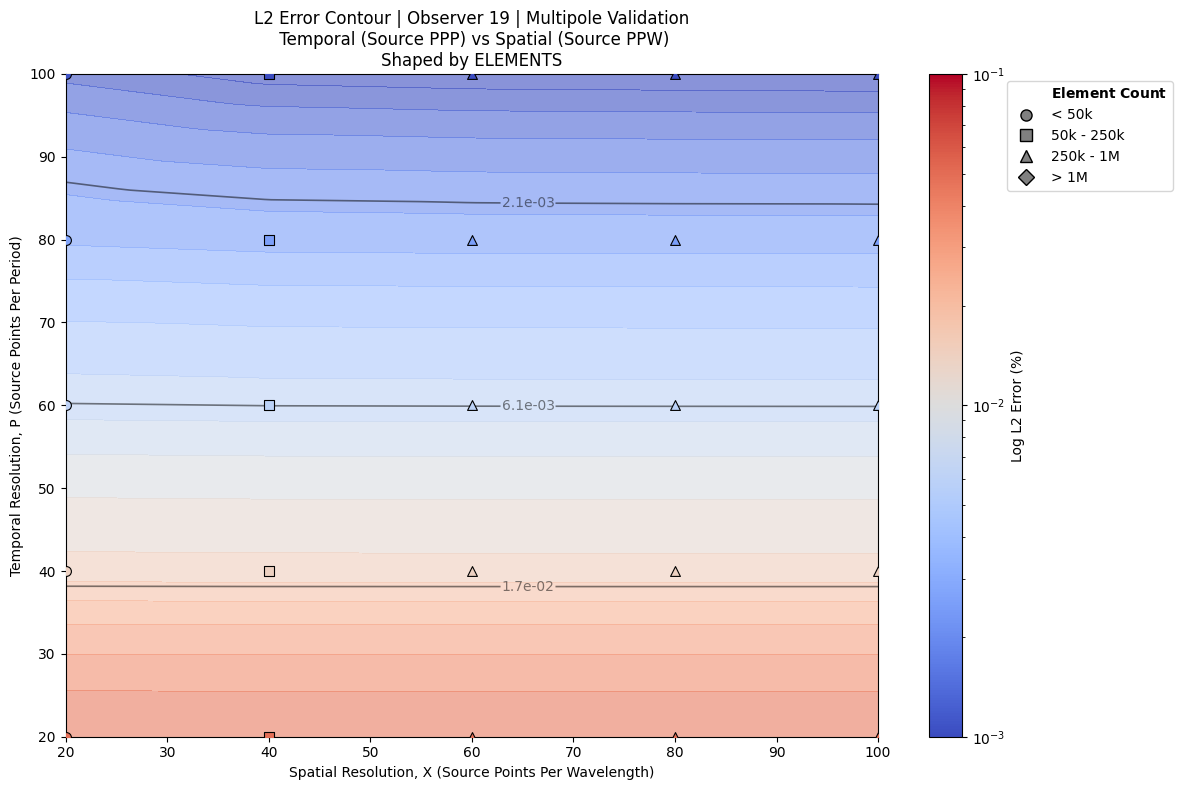

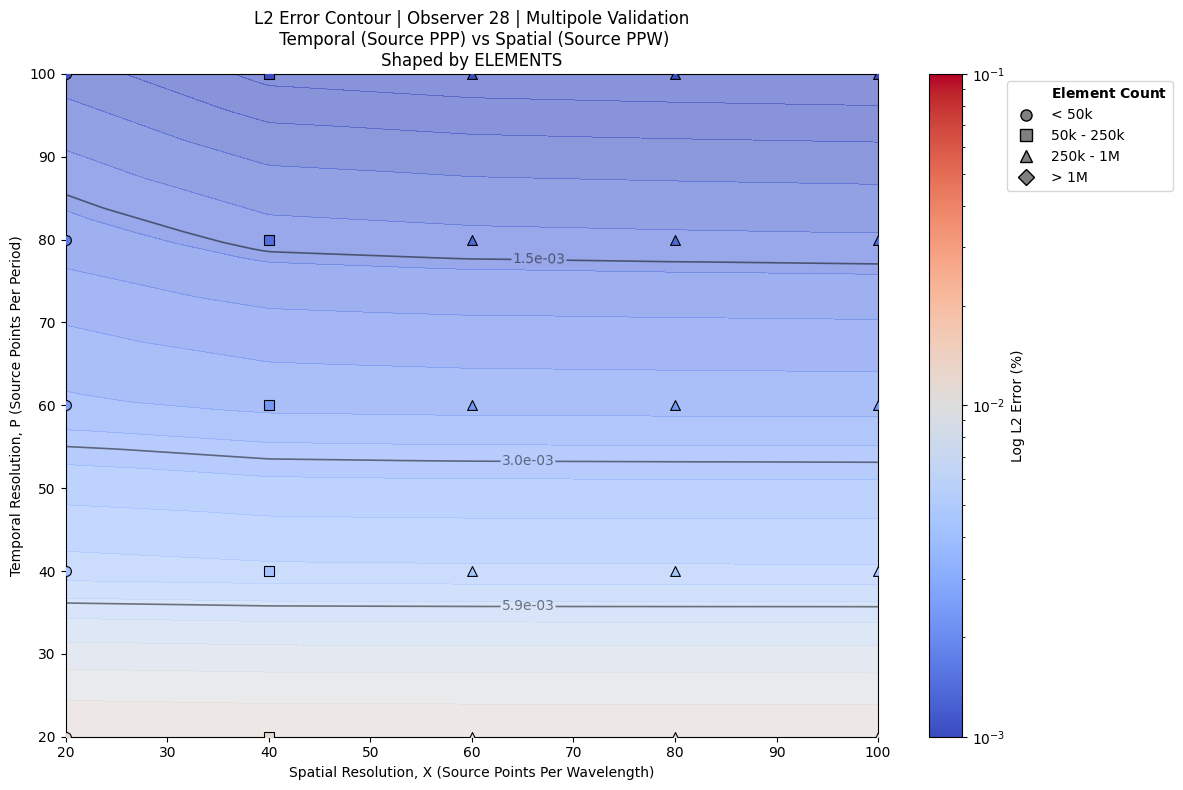

/tmp/ipykernel_19881/3215462399.py:149: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='observer', y='error', palette='coolwarm',


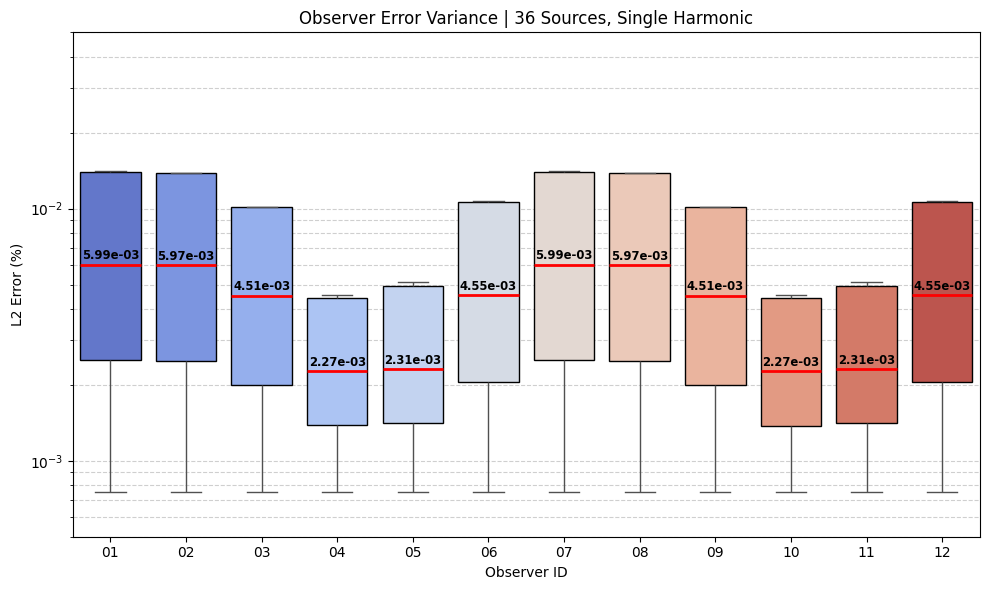

In [30]:
date = '260722'
filepath = Path(f'data_{date}/36sources_xpsweep')
FWHDataset.R = 4.29              
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 107.25
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01', '10', '19', '28']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Multipole Validation', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3                
    )

df = box_plotter(filepath, target_observers=['01','02','03','04','05','06','07','08','09','10','11','12'], use_doppler=False,
                 add_title='36 Sources, Single Harmonic')

In [4]:
# date = '260722' # Update to your actual run date
# filepath = Path(f'data_{date}/TEST_NEW')
# obs_id = ['02']   # Select target observer

# x_fixed = 10
# p_test_vals = [100]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Point Rotor Test Case | 12 Harmonics | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [5]:
# date = '260722' # Update to your actual run date
# filepath = Path(f'data_{date}/TEST')
# obs_id = ['02']   # Select target observer

# x_fixed = 10
# p_test_vals = [10]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Point Rotor Test Case | 12 Harmonics | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [6]:
# date = '260722' # Update to your actual run date
# filepath = Path(f'data_{date}/Compact_Point_Rotor_Test')
# obs_id = ['01']   # Select target observer

# x_fixed = 20
# p_test_vals = [20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Point Rotor Test Case | 12 Harmonics | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [7]:
# date = '260721' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes_nearer-inphase_8obs_50m')
# obs_id = ['01','02','03','04','05']   # Select target observer

# x_fixed = 10
# p_test_vals = [10]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two In-Phase Sources, Distance=0.034m (1/100 Wavelength) \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [8]:
# date = '260721' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes_near-inphase_8obs_50m')
# obs_id = ['01','02','03','04','05']   # Select target observer

# x_fixed = 10
# p_test_vals = [10]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two In-Phase Sources, Distance=0.34m (1/10 Wavelength) \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [9]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes-inphase')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two Sources 3.0m Distance (0.88 X Wavelength), In-Phase \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [10]:
# date = '260721' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes_far-inphase_8obs_50m')
# obs_id = ['01','02','03','04','05']   # Select target observer

# x_fixed = 10
# p_test_vals = [10]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two In-Phase Sources, Distance=20m (5.8X Wavelength) \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [11]:
# date = '260721' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes-inphase_8obs_50m')
# obs_id = ['01','02','03','04','05']   # Select target observer

# x_fixed = 10
# p_test_vals = [10]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two In-Phase Sources Offset X=-1.5 | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [12]:
# date = '260722' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes_further-inphase_8obs_50m')
# obs_id = ['01','02','03','04','05']   # Select target observer

# x_fixed = 10
# p_test_vals = [10]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two In-Phase Sources, Distance=3.4m (1 Wavelength) \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [13]:
# date = '260722' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes_far-inphase_8obs_50m')
# obs_id = ['01','02','03','04','05']   # Select target observer

# x_fixed = 10
# p_test_vals = [10]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two In-Phase Sources, Distance=3.4m (1 Wavelength) \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [14]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/1lobe-offset')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'One Source Offset X=-1.5 | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [15]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/1lobe-centre')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'One Source Centre | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [16]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes-inphase')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two Sources 3.0m Distance (0.88 X), In-Phase \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [17]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/OLDBUILD_2lobes-inphase')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two Sources 3.0m Distance (0.88 X Wavelength), In-Phase \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [18]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes-phaselag')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two Sources 3.0m Distance (0.88 X Wavelength), Phase-Lagged \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [19]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/OLDBUILD_2lobes-phaselag_small_distance')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two Sources Offset 0.0068m (1/500th Wavelength), Phase-Lagged \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [20]:
# date = '260720' # Update to your actual run date
# filepath = Path(f'data_{date}/OLDBUILD_2lobes-inphase_small_distance')
# obs_id = ['01','02','03','04']   # Select target observer

# x_fixed = 10
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Two Sources Offset 0.0068m (1/500th Wavelength), In-Phase \n Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

In [21]:

# date = '260717' # Update to your actual run date
# filepath = Path(f'data_{date}/2lobes-0deg')
# obs_id = ['01','10','19','28']   # Select target observer

# x_fixed = 20
# p_test_vals = [10, 20]

# for obs in obs_id:
#     # 1. Load Analytical Baseline
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     # 2. Load Numerical Datasets (Varying P)
#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     # 3. Plot Time History
#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Temporal Convergence | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         x_axis='absolute'
#     )

# # Load files into FWHDataset objects, zero-padded, up to 36
# ana_datasets = [FWHDataset(filepath=filepath / f'ana_spatial_{i:02d}.dat') for i in range(1, 37)]
# X10_datasets = [FWHDataset(filepath=filepath / f'X10_P20_{i:02d}.dat') for i in range(1, 37)]
# X20_datasets = [FWHDataset(filepath=filepath / f'X20_P20_{i:02d}.dat') for i in range(1, 37)]

# target_times = [0.011, 0.022, 0.033, 0.045]
# for target_time in target_times:
#     FWHPlotter.plot_directivity_snapshot(
#         ana_datasets,
#         X10_datasets,
#         X20_datasets,
#         target_time=target_time,
#         labels=['X=10', 'X=20'],
#         title=f'Pressure Lobes | P = 20 | Time={target_time}',
#         col='P_obs',
#         is_polar=False,
#         legend=True,
#         ylim=1.5
#     )

In [22]:
# date = '260722'
# filepath = Path(f'data_{date}/36sources_xpsweep')
# obs_id = ['01','10','19','28']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 20
# p_test_vals = [20, 40, 60, 90]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'36 Ring Sources | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2'
#     )

# # ==========================================
# # 2. Spatial Directivity (Fixed P, Varying X)
# # ==========================================
# p_fixed = 20
# x_test_vals = [20, 40, 60, 80, 100]

# # Build reference dataset ring (36 observers)
# ana_datasets = [FWHDataset(filepath=filepath / f'ana_spatial_{i:02d}.dat') for i in range(1, 37)]

# # Build comparison dataset rings dynamically
# comp_datasets = []
# comp_labels = []

# for x in x_test_vals:
#     # Check if the entire 36-observer ring exists for this X value
#     x_ring_paths = [filepath / f'X{x}_P{p_fixed}_{i:02d}.dat' for i in range(1, 37)]
    
#     if all(path.exists() for path in x_ring_paths):
#         comp_datasets.append([FWHDataset(filepath=path) for path in x_ring_paths])
#         comp_labels.append(f'X = {x}')
#     else:
#         print(f"Skipping X = {x} (incomplete or missing observer files).")

# target_times = (0.011, 0.022, 0.033, 0.045)
# for target_time in target_times:
#     # Plot using the updated class method
#     FWHPlotter.plot_directivity_snapshot(
#         ana_datasets,
#         *comp_datasets,
#         target_time=target_time, # Interpolates all datasets to this exact steady-state timestamp
#         labels=comp_labels,
#         title=f'Pressure Lobes | Fixed P={p_fixed} | Time at {target_time}s',
#         col='P_obs', 
#         is_polar=False,
#         legend=True,
#         ylim=1.0
#     )

In [23]:

# date = '260716'
# filepath = Path(f'data_{date}/72Sources_Fundamental_Sweep')
# obs_id = ['01','10','19','28']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 30
# p_test_vals = [10, 20, 30, 40]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Temporal Convergence | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2'
#     )

# # ==========================================
# # 2. Spatial Directivity (Fixed P, Varying X)
# # ==========================================
# p_fixed = 30
# x_test_vals = [10, 20, 30, 40]

# # Build reference dataset ring (36 observers)
# ana_datasets = [FWHDataset(filepath=filepath / f'ana_spatial_{i:02d}.dat') for i in range(1, 37)]

# # Build comparison dataset rings dynamically
# comp_datasets = []
# comp_labels = []

# for x in x_test_vals:
#     # Check if the entire 36-observer ring exists for this X value
#     x_ring_paths = [filepath / f'X{x}_P{p_fixed}_{i:02d}.dat' for i in range(1, 37)]
    
#     if all(path.exists() for path in x_ring_paths):
#         comp_datasets.append([FWHDataset(filepath=path) for path in x_ring_paths])
#         comp_labels.append(f'X = {x}')
#     else:
#         print(f"Skipping X = {x} (incomplete or missing observer files).")

# target_times = (0.011, 0.022, 0.033, 0.045)
# for target_time in target_times:
#     # Plot using the updated class method
#     FWHPlotter.plot_directivity_snapshot(
#         ana_datasets,
#         *comp_datasets,
#         target_time=target_time, # Interpolates all datasets to this exact steady-state timestamp
#         labels=comp_labels,
#         title=f'Pressure Lobes | Fixed P={p_fixed} | Time at {target_time}s',
#         col='P_obs', 
#         is_polar=False,
#         legend=True,
#         ylim=1.0
#     )

In [24]:

# date = '260716' # Update to your actual run date
# filepath = Path(f'data_{date}/72Sources_Fundamental_Sweep')
# obs_id = '01'   # Select target observer

# x_fixed = 30
# p_test_vals = [10, 20, 30, 40]

# # 1. Load Analytical Baseline
# ana_path = filepath / f'ana_spatial_{obs_id}.dat'
# ana_dataset = FWHDataset(filepath=ana_path)

# # 2. Load Numerical Datasets (Varying P)
# target_datasets = []
# dataset_labels = []

# for p in p_test_vals:
#     num_path = filepath / f'X{x_fixed}_P{p}_{obs_id}.dat'
#     if num_path.exists():
#         target_datasets.append(FWHDataset(filepath=num_path))
#         dataset_labels.append(f'P = {p}')

# # 3. Plot Time History
# FWHPlotter.plot_pressure(
#     ana_dataset, 
#     *target_datasets, 
#     ref_col='P_obs',
#     labels=dataset_labels,
#     title=f'Temporal Convergence | Observer {obs_id} | Fixed X={x_fixed}',
#     error_method='l2'
# )


# p_fixed = 30
# x_test_vals = [10, 20, 30, 40]
# n_observer = 36

# # Extract observer angles
# angles_deg = np.linspace(0, 360, n_observer, endpoint=False)

# # Setup plot
# fig, ax = plt.subplots(figsize=(8, 5))

# # 1. Extract and Plot Analytical Directivity at t_max
# ana_pressures = []
# for i in range(1, n_observer + 1):
#     ds = FWHDataset(filepath=filepath / f'ana_spatial_{i:02d}.dat')
#     ana_pressures.append(ds.data['P_obs'].iloc[0]) # Grab the final steady-state time step

# ax.plot(angles_deg, ana_pressures, 'k-', lw=2, label='Analytical Baseline')

# # 2. Extract and Plot Numerical Directivities (Varying X)
# colors = ['red', 'blue', 'green', 'orange']
# for idx, x in enumerate(x_test_vals):
#     num_pressures = []
#     valid_run = True
    
#     for i in range(1, n_observer + 1):
#         num_path = filepath / f'X{x}_P{p_fixed}_{i:02d}.dat'
#         if not num_path.exists():
#             valid_run = False
#             break
        
#         ds = FWHDataset(filepath=num_path)
#         num_pressures.append(ds.data['P_obs'].iloc[-1])
        
#     if valid_run:
#         ax.plot(angles_deg, num_pressures, ls='--', marker='o', markersize=4, 
#                 color=colors[idx % len(colors)], label=f'X = {x}')

# ax.set_title(f'Pressure Lobes | Fixed P={p_fixed}', weight='bold')
# ax.set_xlabel('Observer Angle (Degrees)')
# ax.set_ylabel('Pressure (Pa)')
# ax.grid(True, ls='--', alpha=0.6)
# ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
# plt.tight_layout()
# plt.show()

In [25]:
# # 1. Extract and Plot Analytical Directivity at t_max
# ana_pressures = []
# target_time = 0.045 # An exact shared timestamp near the end of the run

# for i in range(1, n_observer + 1):
#     ds = FWHDataset(filepath=filepath / f'ana_spatial_{i:02d}.dat')
#     # Interpolate exact pressure at target_time
#     p_exact = np.interp(target_time, ds.data['Time'], ds.data['P_obs'])
#     ana_pressures.append(p_exact)

# ax.plot(angles_deg, ana_pressures, 'k-', lw=2, label='Analytical Baseline')

# # 2. Extract Numerical
# colors = ['red', 'blue', 'green', 'orange']
# for idx, x in enumerate(x_test_vals):
#     num_pressures = []
#     valid_run = True
    
#     for i in range(1, n_observer + 1):
#         num_path = filepath / f'X{x}_P{p_fixed}_{i:02d}.dat'
#         if not num_path.exists():
#             valid_run = False
#             break
        
#         ds = FWHDataset(filepath=num_path)
#         p_exact = np.interp(target_time, ds.data['Time'], ds.data['P_obs'])
#         num_pressures.append(p_exact)
        
#     if valid_run:
#         ax.plot(angles_deg, num_pressures, ls='--', marker='o', markersize=4, 
#                 color=colors[idx % len(colors)], label=f'X = {x}')

In [26]:
# import pandas as pd

# x_vals = [10, 20, 30, 40]
# p_vals = [10, 20, 30, 40]

# matrix_data = []

# # 1. Calculate L2 Error for all available combinations
# for x in x_vals:
#     for p in p_vals:
#         num_path = filepath / f'X{x}_P{p}_{obs_id}.dat'
        
#         if num_path.exists():
#             num_ds = FWHDataset(filepath=num_path)
            
#             # Use your built-in L2 error method against the analytical dataset
#             l2_err = num_ds.l2_error(ana_dataset, col='P_obs')
            
#             # FWHPlotter.plot_px_contour_space expects 'P', 'X', and 'error' columns
#             matrix_data.append({'P': p, 'X': x, 'error': l2_err})

# df_matrix = pd.DataFrame(matrix_data)

# # 2. Generate Contour Plot
# title_str = f"Error Contour Space | Observer {obs_id} | Fundamental Harmonic"

# # Passing the raw DataFrame directly to your class method
# FWHPlotter.plot_px_contour_space(
#     df_matrix, 
#     use_doppler=False, 
#     add_title=title_str
# )